# Segundo parcial PLN II/2026 — Clasificación automática de comentarios universitarios
**Problema de investigación:** ¿Qué representación de los textos (BoW vs TF-IDF) y qué algoritmo (Naive Bayes vs SVM) dan mejores resultados al clasificar comentarios?

**Objetivo:** desarrollar y evaluar un clasificador usando representación vectorial, reducción de dimensionalidad (PCA) y aprendizaje automático.

Contenido: Fase 1 Preparación · Fase 2 BoW y TF-IDF · Fase 3 PCA · Fase 4 Clasificadores · Fase 5 Análisis crítico.
> Para ejecutar: `Run All`. El archivo `comentarios_universitarios_120.xlsx` debe estar en la misma carpeta.

In [1]:
import os, re, unicodedata, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_colwidth', 90)
SEED = 42                      # semilla fija: resultados reproducibles
os.makedirs('figuras', exist_ok=True)
COLORES = {'Positivo':'#2a9d8f', 'Negativo':'#e76f51', 'Consulta':'#264653'}

## FASE 1. Preparación y exploración
### 1.1 Cargar el conjunto de datos

In [2]:
df = pd.read_excel('comentarios_universitarios_120.xlsx')
print('Dimensiones:', df.shape)
print('Nulos:', df.isna().sum().sum(), '| Duplicados:', df.duplicated().sum())
print(df['categoria'].value_counts().to_string())
df['n_palabras'] = df['comentario'].str.split().str.len()
print('\nPalabras por comentario: media = %.1f, mín = %d, máx = %d' % (df.n_palabras.mean(), df.n_palabras.min(), df.n_palabras.max()))
df[['comentario','categoria']].groupby('categoria').head(2)

Dimensiones: (120, 2)
Nulos: 0 | Duplicados: 0
categoria
Positivo    40
Negativo    40
Consulta    40

Palabras por comentario: media = 9.6, mín = 7, máx = 12


,comentario,categoria
0,La docente explicó el tema con ejemplos claros y fáciles de comprender.,Positivo
1,La plataforma virtual funciona bien y permite entregar tareas sin problemas.,Positivo
40,La plataforma virtual se bloquea cuando intento subir una tarea.,Negativo
41,No puedo completar la inscripción porque el sistema muestra un error.,Negativo
80,¿Dónde puedo consultar el calendario académico del próximo semestre?,Consulta
81,¿Cuál es el procedimiento para inscribirme en una materia electiva?,Consulta


**Lectura:** 120 comentarios, 3 clases perfectamente balanceadas (40/40/40), sin nulos ni duplicados. Con clases balanceadas, accuracy es razonable, pero igual se reportan precisión, recall y F1 macro.

### 1.2 Limpieza de textos
Decisiones:
- **Minúsculas** y **sin tildes** (unifica *inscripción* / *inscripcion*).
- **Puntuación eliminada**, pero antes se marca `¿?` con el token `pregunta` (señal clave de *Consulta*).
- **Stop words** eliminadas (artículos, preposiciones, etc.) **conservando las negaciones** (*no, sin, nunca, tampoco, ni*), porque "no funciona" y "funciona" significan lo contrario.

In [3]:
STOP_WORDS = {
 'el','la','los','las','un','una','unos','unas','lo','al','del','de','a','en','y','o','u','e','que','con','por','para',
 'se','su','sus','mi','mis','es','son','fue','fueron','ser','esta','este','estos','estas','esa','ese','mas','muy','le','les',
 'me','te','nos','como','pero','si','ya','hay','han','ha','he','porque','cuando','donde','cual','cuales','sobre','entre','desde',
 'hasta','tiene','tienen','tengo'}

def quitar_tildes(t):
    return ''.join(c for c in unicodedata.normalize('NFD', t) if unicodedata.category(c) != 'Mn')

def limpiar(texto, quitar_stop=True):
    t = str(texto).lower()
    t = ('pregunta ' if ('?' in t or '¿' in t) else '') + t
    t = quitar_tildes(t)
    t = re.sub(r'[^a-z0-9\s]', ' ', t)
    toks = re.sub(r'\s+', ' ', t).strip().split()
    if quitar_stop: toks = [w for w in toks if w not in STOP_WORDS]
    return ' '.join(toks)

df['texto_limpio'] = df['comentario'].apply(limpiar)
print('Textos vacíos tras limpiar:', (df.texto_limpio == '').sum())
df[['comentario','texto_limpio','categoria']].sample(6, random_state=SEED)

Textos vacíos tras limpiar: 0


,comentario,texto_limpio,categoria
44,En secretaría nadie respondió durante varios días a mi solicitud.,secretaria nadie respondio durante varios dias solicitud,Negativo
47,El aula está sucia y varias luces no funcionan.,aula sucia varias luces no funcionan,Negativo
4,El personal administrativo respondió amablemente a mis consultas.,personal administrativo respondio amablemente consultas,Positivo
55,La aplicación móvil muestra horarios que ya fueron modificados.,aplicacion movil muestra horarios modificados,Negativo
26,Las clases combinan teoría y práctica de manera equilibrada.,clases combinan teoria practica manera equilibrada,Positivo
64,No recibí orientación adecuada para elegir las materias del semestre.,no recibi orientacion adecuada elegir materias semestre,Negativo


### 1.3 Separación entrenamiento / prueba (80 % / 20 %)
Partición **estratificada** (mantiene 1/3 por clase) con semilla fija. **Todos** los modelos y PCA usan esta misma partición.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df['texto_limpio'], df['categoria'], test_size=0.20, random_state=SEED, stratify=df['categoria'])
idx_test = X_test.index
print('Train:', len(X_train), '| Test:', len(X_test))
pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()})

Train: 96 | Test: 24


,train,test
categoria,,
Consulta,32,8
Negativo,32,8
Positivo,32,8


## FASE 2. Representación vectorial
Los vectorizadores se **ajustan solo con entrenamiento** (`fit_transform` en train, `transform` en test) para evitar filtrar información del conjunto de prueba.
### 2.1 Bag of Words (BoW)

In [5]:
bow = CountVectorizer()
Xtr_bow = bow.fit_transform(X_train); Xte_bow = bow.transform(X_test)
vocab = bow.get_feature_names_out()
print('Matriz BoW train:', Xtr_bow.shape, '| test:', Xte_bow.shape)
print('Vocabulario:', len(vocab), 'términos | Densidad: %.1f %% (resto son ceros)' % (100*Xtr_bow.nnz/np.prod(Xtr_bow.shape)))
bow_df = pd.DataFrame(Xtr_bow.toarray(), columns=vocab, index=X_train.index)
# Primeros 3 documentos, solo columnas con valor > 0
for i in range(3):
    fila = bow_df.iloc[i]; print(f'\nDoc {bow_df.index[i]} [{y_train.iloc[i]}]: "{X_train.iloc[i]}"'); print(fila[fila>0].to_dict())

Matriz BoW train: (96, 347) | test: (24, 347)
Vocabulario: 347 términos | Densidad: 1.7 % (resto son ceros)

Doc 88 [Consulta]: "pregunta habilitara formulario inscripcion"
{'formulario': 1, 'habilitara': 1, 'inscripcion': 1, 'pregunta': 1}

Doc 86 [Consulta]: "pregunta horario atencion biblioteca"
{'atencion': 1, 'biblioteca': 1, 'horario': 1, 'pregunta': 1}

Doc 21 [Positivo]: "grupos estudio ayudan resolver dudas companeros"
{'ayudan': 1, 'companeros': 1, 'dudas': 1, 'estudio': 1, 'grupos': 1, 'resolver': 1}


**Explicación de los vectores:** cada comentario es un vector de largo = tamaño del vocabulario; cada posición cuenta cuántas veces aparece esa palabra. Como cada comentario tiene ~6 palabras útiles y el vocabulario tiene cientos, casi todo son ceros (matriz **dispersa**).

**Palabras que distinguen cada categoría (BoW):** las que más aparecen en una categoría.

In [6]:
top = {}
for c in ['Positivo','Negativo','Consulta']:
    s = bow_df.loc[y_train[y_train==c].index].sum().sort_values(ascending=False).head(8)
    top[c] = [f'{w} ({int(n)})' for w, n in s.items()]
pd.DataFrame(top)

,Positivo,Negativo,Consulta
0,plataforma (3),no (12),pregunta (32)
1,biblioteca (2),muestra (4),puedo (8)
2,virtual (2),varias (3),procedimiento (3)
3,universidad (2),laboratorio (3),consultar (3)
4,bien (2),sistema (3),disponibles (3)
5,permite (2),aula (3),publican (2)
6,comprender (2),suficientes (3),quien (2)
7,sistema (2),virtual (2),proximo (2)


### 2.2 TF-IDF

In [7]:
tfidf = TfidfVectorizer()
Xtr_tfidf = tfidf.fit_transform(X_train); Xte_tfidf = tfidf.transform(X_test)
tf_df = pd.DataFrame(Xtr_tfidf.toarray(), columns=tfidf.get_feature_names_out(), index=X_train.index)
print('Matriz TF-IDF train:', Xtr_tfidf.shape)
# >= 5 términos con sus pesos en varios documentos
for i in [0, 40, 80]:
    fila = tf_df.iloc[i]; fila = fila[fila>0].sort_values(ascending=False)
    print(f'\nDoc {tf_df.index[i]} [{y_train.iloc[i]}]: "{X_train.iloc[i]}"')
    print(fila.round(3).to_string())

Matriz TF-IDF train: (96, 347)

Doc 88 [Consulta]: "pregunta habilitara formulario inscripcion"
habilitara     0.618
formulario     0.566
inscripcion    0.479
pregunta       0.263

Doc 55 [Negativo]: "aplicacion movil muestra horarios modificados"
aplicacion     0.475
modificados    0.475
movil          0.475
horarios       0.435
muestra        0.368

Doc 110 [Consulta]: "pregunta puedo consultar fechas pago matricula"
matricula    0.509
pago         0.466
fechas       0.436
consultar    0.413
puedo        0.341
pregunta     0.216


In [8]:
# Tabla comparativa BoW vs TF-IDF para un mismo documento
i = 0
cmp = pd.DataFrame({'BoW (conteo)': bow_df.iloc[i], 'TF-IDF (peso)': tf_df.iloc[i].round(3)})
cmp = cmp[cmp['BoW (conteo)']>0].sort_values('TF-IDF (peso)', ascending=False)
print('Documento:', X_train.iloc[i]); cmp

Documento: pregunta habilitara formulario inscripcion


,BoW (conteo),TF-IDF (peso)
habilitara,1,0.618
formulario,1,0.566
inscripcion,1,0.479
pregunta,1,0.263


In [9]:
# Palabras con IDF más bajo (comunes) vs más alto (raras)
idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print('IDF más BAJO (aparecen en muchos comentarios):'); print(idf.head(6).round(2).to_string())
print('\nIDF más ALTO (aparecen en 1 comentario):'); print(idf.tail(4).round(2).to_string())

IDF más BAJO (aparecen en muchos comentarios):
pregunta       2.08
no             3.01
puedo          3.27
laboratorio    3.63
plataforma     3.63
sistema        3.63

IDF más ALTO (aparecen en 1 comentario):
varios        4.88
accede        4.88
academicos    4.88
academica     4.88


**Interpretación:** TF-IDF = TF × IDF. Palabras como `pregunta` o `no` aparecen en muchos documentos → IDF bajo → peso menor que palabras raras y específicas (p. ej. *biblioteca*, *laboratorio*). Un peso bajo **no significa que la palabra sea irrelevante en el idioma**, sino que **distingue poco** un comentario de otro. (Nota: `pregunta` igualmente es muy útil para detectar *Consulta*, porque aparece casi solo en esa clase; la importancia para clasificar depende de la clase, no solo del IDF.)

## FASE 3. Reducción de dimensionalidad (PCA)
PCA se ajusta **solo con TF-IDF de entrenamiento**. Test se proyecta con la transformación ya aprendida.

In [10]:
pca = PCA(random_state=SEED)
Ztr_full = pca.fit_transform(Xtr_tfidf.toarray())
var = pca.explained_variance_ratio_; acum = np.cumsum(var)
tabla_var = pd.DataFrame({'Componente':[f'PC{i+1}' for i in range(10)],
                          'Varianza explicada (%)': (100*var[:10]).round(2),
                          'Varianza acumulada (%)': (100*acum[:10]).round(2)})
print(tabla_var.to_string(index=False))
for p in (0.50, 0.80, 0.90):
    print(f'Componentes para {int(p*100)} % de varianza: {np.argmax(acum>=p)+1}  (de {Xtr_tfidf.shape[1]} dimensiones originales)')

Componente  Varianza explicada (%)  Varianza acumulada (%)
       PC1                    2.71                    2.71
       PC2                    2.46                    5.17
       PC3                    2.29                    7.46
       PC4                    2.03                    9.49
       PC5                    1.94                   11.44
       PC6                    1.85                   13.29
       PC7                    1.78                   15.07
       PC8                    1.76                   16.83
       PC9                    1.67                   18.50
      PC10                    1.65                   20.16
Componentes para 50 % de varianza: 32  (de 347 dimensiones originales)
Componentes para 80 % de varianza: 62  (de 347 dimensiones originales)
Componentes para 90 % de varianza: 76  (de 347 dimensiones originales)


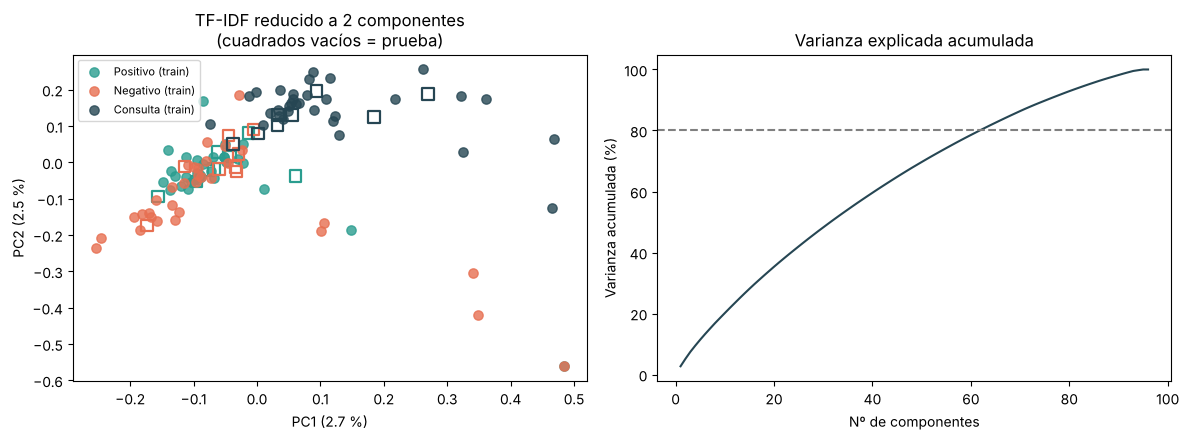

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
# (a) dispersión en PC1-PC2 (train relleno, test con borde)
Zte = pca.transform(Xte_tfidf.toarray())
for c, col in COLORES.items():
    m = (y_train.values == c); ax[0].scatter(Ztr_full[m,0], Ztr_full[m,1], c=col, label=f'{c} (train)', alpha=.8, s=45)
    m = (y_test.values == c);  ax[0].scatter(Zte[m,0], Zte[m,1], facecolors='none', edgecolors=col, marker='s', s=70, linewidths=1.6)
ax[0].set_xlabel(f'PC1 ({100*var[0]:.1f} %)'); ax[0].set_ylabel(f'PC2 ({100*var[1]:.1f} %)')
ax[0].set_title('TF-IDF reducido a 2 componentes\n(cuadrados vacíos = prueba)'); ax[0].legend(fontsize=8)
# (b) varianza acumulada
ax[1].plot(range(1, len(acum)+1), 100*acum, color='#264653'); ax[1].axhline(80, ls='--', c='gray')
ax[1].set_xlabel('Nº de componentes'); ax[1].set_ylabel('Varianza acumulada (%)'); ax[1].set_title('Varianza explicada acumulada')
plt.tight_layout(); plt.savefig('figuras/pca_dispersion.png', dpi=160); plt.show()

### Comparación con la representación original
La representación original tiene cientos de dimensiones (una por palabra). Para ver 2 de ellas "sin reducir", se grafican dos palabras originales, como `pregunta` y `no`, frente a los 2 componentes de PCA.

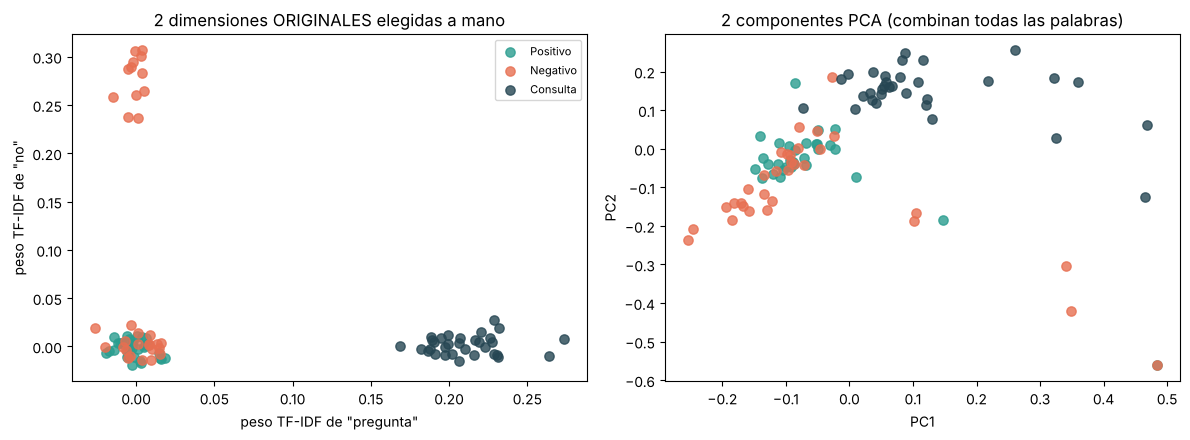

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
rng = np.random.RandomState(SEED)
for c, col in COLORES.items():
    m = (y_train.values == c)
    ax[0].scatter(tf_df['pregunta'].values[m] + rng.normal(0,.01,m.sum()), tf_df['no'].values[m] + rng.normal(0,.01,m.sum()), c=col, label=c, alpha=.8, s=45)
    ax[1].scatter(Ztr_full[m,0], Ztr_full[m,1], c=col, label=c, alpha=.8, s=45)
ax[0].set_xlabel('peso TF-IDF de "pregunta"'); ax[0].set_ylabel('peso TF-IDF de "no"'); ax[0].set_title('2 dimensiones ORIGINALES elegidas a mano')
ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2'); ax[1].set_title('2 componentes PCA (combinan todas las palabras)')
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig('figuras/pca_vs_original.png', dpi=160); plt.show()

In [13]:
# Cuantificar separación visual: ¿un clasificador simple en solo 2 componentes acierta?
from sklearn.svm import LinearSVC as _L
for k in (2, 10, 30):
    m = _L(random_state=SEED).fit(Ztr_full[:,:k], y_train)
    print(f'SVM sobre los primeros {k:>2} componentes PCA -> accuracy en prueba: {accuracy_score(y_test, m.predict(Zte[:,:k])):.3f}')
print(f'(SVM sobre las {Xtr_tfidf.shape[1]} dimensiones TF-IDF completas -> '
      f'{accuracy_score(y_test, _L(random_state=SEED).fit(Xtr_tfidf, y_train).predict(Xte_tfidf)):.3f})')

SVM sobre los primeros  2 componentes PCA -> accuracy en prueba: 0.625
SVM sobre los primeros 10 componentes PCA -> accuracy en prueba: 0.708
SVM sobre los primeros 30 componentes PCA -> accuracy en prueba: 0.625
(SVM sobre las 347 dimensiones TF-IDF completas -> 0.583)


**Interpretación PCA:**
- Los 2 primeros componentes explican solo ~5 % de la varianza (2.7 % + 2.5 %) y harían falta ~62 componentes para llegar a 80 %. Es lo esperado en texto: cada palabra aporta poca varianza y la información está repartida en cientos de dimensiones dispersas.
- En el gráfico, **Consulta (azul oscuro) se separa bien** de las otras dos (arriba/derecha). **Positivo y Negativo se mezclan** en la zona central-izquierda, con solapamiento fuerte.
- Esto coincide con el gráfico de dimensiones originales: `pregunta` aísla *Consulta*; `no` aísla solo una parte de *Negativo*; el resto de Positivo/Negativo comparte poca estructura léxica.
- El SVM sobre 2, 10, 30 componentes o las 347 dimensiones da 58–71 % en prueba: son diferencias de 1–3 comentarios (el test solo tiene 24), es decir **ruido**. Conclusión: PCA **no mejora** la clasificación aquí; se usa como análisis exploratorio y no se incluye en el modelo final.

## FASE 4. Entrenamiento de clasificadores
4 modelos, **mismo** conjunto de prueba:
| Representación | Clasificador |
|---|---|
| BoW | Naive Bayes (`MultinomialNB`) |
| TF-IDF | Naive Bayes |
| BoW | SVM (`LinearSVC`, kernel lineal) |
| TF-IDF | SVM |

In [14]:
modelos = {
  ('BoW','Naive Bayes'):   (MultinomialNB(),            Xtr_bow,   Xte_bow),
  ('TF-IDF','Naive Bayes'):(MultinomialNB(),            Xtr_tfidf, Xte_tfidf),
  ('BoW','SVM'):           (LinearSVC(random_state=SEED), Xtr_bow,   Xte_bow),
  ('TF-IDF','SVM'):        (LinearSVC(random_state=SEED), Xtr_tfidf, Xte_tfidf),
}
filas, preds = [], {}
for (rep, clf), (m, Xa, Xb) in modelos.items():
    m.fit(Xa, y_train); p = m.predict(Xb); preds[(rep, clf)] = p
    filas.append({'Representación':rep, 'Clasificador':clf,
        'Accuracy':accuracy_score(y_test,p),
        'Precisión macro':precision_score(y_test,p,average='macro'),
        'Recall macro':recall_score(y_test,p,average='macro'),
        'F1 macro':f1_score(y_test,p,average='macro')})
resultados = pd.DataFrame(filas).round(4)
resultados.to_csv('resultados_prueba.csv', index=False)
resultados

,Representación,Clasificador,Accuracy,Precisión macro,Recall macro,F1 macro
0,BoW,Naive Bayes,0.5417,0.6540,0.5417,0.4986
1,TF-IDF,Naive Bayes,0.4167,0.3889,0.4167,0.3783
2,BoW,SVM,0.5833,0.5833,0.5833,0.5833
3,TF-IDF,SVM,0.5833,0.5481,0.5833,0.5557


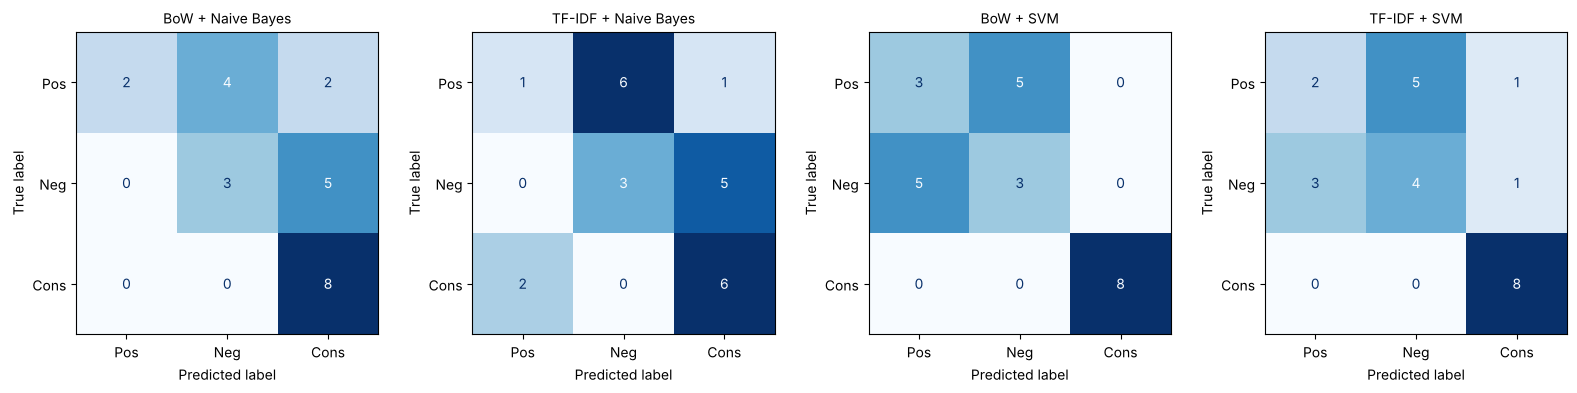

===== ('BoW', 'SVM')
              precision    recall  f1-score   support

    Consulta      1.000     1.000     1.000         8
    Negativo      0.375     0.375     0.375         8
    Positivo      0.375     0.375     0.375         8

    accuracy                          0.583        24
   macro avg      0.583     0.583     0.583        24
weighted avg      0.583     0.583     0.583        24

===== ('TF-IDF', 'SVM')
              precision    recall  f1-score   support

    Consulta      0.800     1.000     0.889         8
    Negativo      0.444     0.500     0.471         8
    Positivo      0.400     0.250     0.308         8

    accuracy                          0.583        24
   macro avg      0.548     0.583     0.556        24
weighted avg      0.548     0.583     0.556        24

===== ('BoW', 'Naive Bayes')
              precision    recall  f1-score   support

    Consulta      0.533     1.000     0.696         8
    Negativo      0.429     0.375     0.400         8
 

In [15]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
for ax_, ((rep, clf), p) in zip(axs, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p, labels=['Positivo','Negativo','Consulta']),
                           display_labels=['Pos','Neg','Cons']).plot(ax=ax_, colorbar=False, cmap='Blues')
    ax_.set_title(f'{rep} + {clf}', fontsize=10)
plt.tight_layout(); plt.savefig('figuras/matrices_confusion.png', dpi=160); plt.show()
for k in [('BoW','SVM'),('TF-IDF','SVM'),('BoW','Naive Bayes')]:
    print('=====', k); print(classification_report(y_test, preds[k], digits=3))

### Validación más robusta (pregunta crítica 7)
El conjunto de prueba tiene solo **24** comentarios: un error cambia la accuracy en ~4 puntos. Para saber si una diferencia se debe a la representación y no a la partición, se repite una **validación cruzada estratificada 5×5** (25 particiones distintas). El vectorizador va **dentro del pipeline**, así se reajusta en cada pliegue (sin fuga de información).

In [16]:
rkf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
pipes = {
  ('BoW','Naive Bayes'):   make_pipeline(CountVectorizer(), MultinomialNB()),
  ('TF-IDF','Naive Bayes'):make_pipeline(TfidfVectorizer(), MultinomialNB()),
  ('BoW','SVM'):           make_pipeline(CountVectorizer(), LinearSVC(random_state=SEED)),
  ('TF-IDF','SVM'):        make_pipeline(TfidfVectorizer(), LinearSVC(random_state=SEED)),
}
cv_rows = []
for (rep, clf), pipe in pipes.items():
    r = cross_validate(pipe, df['texto_limpio'], df['categoria'], cv=rkf, scoring=['accuracy','f1_macro'])
    cv_rows.append({'Representación':rep,'Clasificador':clf,
        'Accuracy (media)':r['test_accuracy'].mean(), 'Accuracy (desv.)':r['test_accuracy'].std(),
        'F1 macro (media)':r['test_f1_macro'].mean(),  'F1 macro (desv.)':r['test_f1_macro'].std()})
cv = pd.DataFrame(cv_rows).round(4); cv.to_csv('resultados_validacion_cruzada.csv', index=False); cv

,Representación,Clasificador,Accuracy (media),Accuracy (desv.),F1 macro (media),F1 macro (desv.)
0,BoW,Naive Bayes,0.6200,0.0776,0.5881,0.0912
1,TF-IDF,Naive Bayes,0.5583,0.0850,0.5267,0.0963
2,BoW,SVM,0.7350,0.0525,0.7278,0.0557
3,TF-IDF,SVM,0.6717,0.0670,0.6616,0.0702


## FASE 5. Análisis crítico
### 5.1 Revisión de errores en el conjunto de prueba

In [17]:
test_df = df.loc[idx_test, ['comentario','categoria']].copy()
hay_error = False
for (rep, clf), p in preds.items():
    test_df[f'{rep}+{clf}'] = p
cols = [c for c in test_df.columns if '+' in c]
err = test_df[test_df[cols].ne(test_df['categoria'], axis=0).any(axis=1)]
print('Comentarios de prueba con al menos un error:', len(err), 'de', len(test_df))
err

Comentarios de prueba con al menos un error: 15 de 24


,comentario,categoria,BoW+Naive Bayes,TF-IDF+Naive Bayes,BoW+SVM,TF-IDF+SVM
17,La conexión a internet del campus permitió trabajar sin interrupciones.,Positivo,Negativo,Negativo,Negativo,Negativo
43,La biblioteca cierra antes de que terminen las clases de la tarde.,Negativo,Negativo,Negativo,Positivo,Negativo
20,La aplicación móvil facilita consultar horarios y avisos.,Positivo,Negativo,Negativo,Negativo,Negativo
79,La impresora de la facultad está fuera de servicio desde hace semanas.,Negativo,Consulta,Consulta,Positivo,Positivo
14,Las instrucciones para el examen fueron claras desde el inicio.,Positivo,Negativo,Negativo,Negativo,Negativo
13,El laboratorio cuenta con computadoras adecuadas para las actividades.,Positivo,Negativo,Negativo,Positivo,Positivo
78,Las fechas de evaluación de varias materias coinciden el mismo día.,Negativo,Consulta,Consulta,Positivo,Positivo
22,La orientación para estudiantes nuevos fue muy útil.,Positivo,Consulta,Consulta,Positivo,Consulta
48,El horario publicado tiene materias programadas a la misma hora.,Negativo,Consulta,Consulta,Positivo,Consulta
87,¿Cómo reservo un equipo para utilizar el laboratorio de informática?,Consulta,Consulta,Positivo,Consulta,Consulta


### 5.2 Prueba con cinco comentarios nuevos
Incluyen casos más difíciles que los de entrenamiento (vocabulario nuevo, ortografía descuidada, ironía) para evaluar la **generalización**.

In [18]:
nuevos = [
 ('Excelente atención en la biblioteca, encontré todos los libros que necesitaba.', 'Positivo'),
 ('El wifi del campus se cae constantemente y no puedo conectarme a las clases.', 'Negativo'),
 ('¿Hasta qué fecha puedo pagar la matrícula del semestre?', 'Consulta'),
 ('Que genial, otra vez sin luz en el laboratorio el día del examen.', 'Negativo'),   # ironía
 ('ola, nesesito saber como solicito mi certificado de notas', 'Consulta'),         # ortografía y sin ¿?
]
nuevos_df = pd.DataFrame(nuevos, columns=['comentario','real'])
Xn = nuevos_df['comentario'].apply(limpiar)
out = nuevos_df.copy()
tra = {('BoW','Naive Bayes'):(MultinomialNB().fit(Xtr_bow,y_train), bow),
       ('TF-IDF','Naive Bayes'):(MultinomialNB().fit(Xtr_tfidf,y_train), tfidf),
       ('BoW','SVM'):(LinearSVC(random_state=SEED).fit(Xtr_bow,y_train), bow),
       ('TF-IDF','SVM'):(LinearSVC(random_state=SEED).fit(Xtr_tfidf,y_train), tfidf)}
for (rep, clf), (m, vec) in tra.items():
    out[f'{rep}+{clf}'] = m.predict(vec.transform(Xn))
aciertos = {k: int((out[k]==out['real']).sum()) for k in out.columns if '+' in k}
print('Aciertos sobre 5 comentarios nuevos:', aciertos)
out

Aciertos sobre 5 comentarios nuevos: {'BoW+Naive Bayes': 5, 'TF-IDF+Naive Bayes': 5, 'BoW+SVM': 4, 'TF-IDF+SVM': 4}


,comentario,real,BoW+Naive Bayes,TF-IDF+Naive Bayes,BoW+SVM,TF-IDF+SVM
0,"Excelente atención en la biblioteca, encontré todos los libros que necesitaba.",Positivo,Positivo,Positivo,Positivo,Positivo
1,El wifi del campus se cae constantemente y no puedo conectarme a las clases.,Negativo,Negativo,Negativo,Negativo,Negativo
2,¿Hasta qué fecha puedo pagar la matrícula del semestre?,Consulta,Consulta,Consulta,Consulta,Consulta
3,"Que genial, otra vez sin luz en el laboratorio el día del examen.",Negativo,Negativo,Negativo,Negativo,Negativo
4,"ola, nesesito saber como solicito mi certificado de notas",Consulta,Consulta,Consulta,Positivo,Positivo


In [19]:
# Probabilidades de Naive Bayes (TF-IDF) para ver cómo "razona" con cada comentario nuevo
nb = tra[('TF-IDF','Naive Bayes')][0]
prob = pd.DataFrame(nb.predict_proba(tfidf.transform(Xn)), columns=nb.classes_).round(3)
prob.insert(0, 'texto limpio', Xn.values); prob

,texto limpio,Consulta,Negativo,Positivo
0,excelente atencion biblioteca encontre todos libros necesitaba,0.305,0.275,0.420
1,wifi campus cae constantemente no puedo conectarme clases,0.262,0.481,0.257
2,pregunta fecha puedo pagar matricula semestre,0.637,0.198,0.165
3,genial otra vez sin luz laboratorio dia examen,0.270,0.437,0.294
4,ola nesesito saber solicito certificado notas,0.401,0.297,0.302


In [20]:
# ¿Qué palabras empujan hacia cada clase? (log-probabilidades de Naive Bayes y pesos del SVM)
nbm = tra[('TF-IDF','Naive Bayes')][0]; vocab_t = tfidf.get_feature_names_out()
lp = pd.DataFrame(nbm.feature_log_prob_.T, index=vocab_t, columns=nbm.classes_)
print('Palabras más características por clase (Naive Bayes, mayor log P(palabra|clase) - media del resto):')
for c in nbm.classes_:
    d = lp[c] - lp.drop(columns=c).mean(axis=1); print(f'  {c}:', ', '.join(d.sort_values(ascending=False).head(8).index))
svm = tra[('TF-IDF','SVM')][0]
print('\nPalabras con mayor peso en la frontera del SVM:')
for c, w in zip(svm.classes_, svm.coef_):
    print(f'  {c}:', ', '.join(pd.Series(w, index=vocab_t).sort_values(ascending=False).head(8).index))

Palabras más características por clase (Naive Bayes, mayor log P(palabra|clase) - media del resto):
  Consulta: pregunta, puedo, procedimiento, materia, estudiante, consultar, proximo, debo
  Negativo: no, suficientes, varias, muestra, computadoras, error, aula, demasiado
  Positivo: rapido, publico, libros, teoria, personal, oriento, estudio, comprender

Palabras con mayor peso en la frontera del SVM:
  Consulta: pregunta, puedo, procedimiento, oficina, quien, debo, estudiante, accede
  Negativo: no, muestra, desactualizados, demasiado, varias, incorrectas, tarde, veces
  Positivo: claramente, publico, estudio, interesantes, rapido, personal, grupo, oriento


### 5.3 Mejoras probadas
Se prueban dos ideas con la **misma validación cruzada 5×5**:
1. **Bigramas** (1-2 gramas): capturar contexto ("no puedo", "sin luz").
2. **Conservar las stop words** (con "no", "sin", etc. ya conservadas; ahora también "que", "para", "como"…): palabras funcionales como *hasta*, *desde*, *para* pueden ser pistas del estilo de una queja o consulta.

In [21]:
df['texto_con_stop'] = df['comentario'].apply(lambda t: limpiar(t, quitar_stop=False))
Xn_stop = nuevos_df['comentario'].apply(lambda t: limpiar(t, quitar_stop=False))
idx_tr = X_train.index
mejora = {
 'BoW + SVM (base)':               (make_pipeline(CountVectorizer(), LinearSVC(random_state=SEED)), 'texto_limpio'),
 'BoW + SVM, con stop words':      (make_pipeline(CountVectorizer(), LinearSVC(random_state=SEED)), 'texto_con_stop'),
 'TF-IDF + SVM (base)':            (make_pipeline(TfidfVectorizer(), LinearSVC(random_state=SEED)), 'texto_limpio'),
 'TF-IDF + SVM, con stop words':   (make_pipeline(TfidfVectorizer(), LinearSVC(random_state=SEED)), 'texto_con_stop'),
 'TF-IDF 1-2 gramas + SVM':        (make_pipeline(TfidfVectorizer(ngram_range=(1,2)), LinearSVC(random_state=SEED)), 'texto_limpio'),
 'TF-IDF 1-2 gramas + NB':         (make_pipeline(TfidfVectorizer(ngram_range=(1,2)), MultinomialNB()), 'texto_limpio'),
}
rows=[]
for n, (p, col) in mejora.items():
    r = cross_validate(p, df[col], df['categoria'], cv=rkf, scoring=['accuracy','f1_macro'])
    p.fit(df.loc[idx_tr, col], y_train)
    nuevos_x = Xn_stop if col=='texto_con_stop' else Xn
    rows.append({'Modelo':n,'Acc CV':r['test_accuracy'].mean(),'Desv.':r['test_accuracy'].std(),'F1 CV':r['test_f1_macro'].mean(),
                 'Acc prueba': accuracy_score(y_test, p.predict(df.loc[idx_test, col])),
                 'Aciertos en 5 nuevos': int((p.predict(nuevos_x)==nuevos_df['real']).sum())})
mej = pd.DataFrame(rows).round(4); mej.to_csv('resultados_mejora.csv', index=False); mej

,Modelo,Acc CV,Desv.,F1 CV,Acc prueba,Aciertos en 5 nuevos
0,BoW + SVM (base),0.7350,0.0525,0.7278,0.5833,4
1,"BoW + SVM, con stop words",0.7517,0.0606,0.7429,0.6250,4
2,TF-IDF + SVM (base),0.6717,0.0670,0.6616,0.5833,4
3,"TF-IDF + SVM, con stop words",0.7150,0.0585,0.7060,0.6250,5
4,TF-IDF 1-2 gramas + SVM,0.6350,0.0793,0.6188,0.5000,4
5,TF-IDF 1-2 gramas + NB,0.5367,0.0819,0.5033,0.3750,5


**Lectura:** los bigramas **no** mejoran (con solo 96 textos de entrenamiento, más atributos = más dispersión y sobreajuste). Conservar stop words da una ganancia pequeña (~1-2 puntos), **menor que la desviación estándar entre particiones (~5 puntos)**, por lo que no es concluyente. La mejora con mayor potencial real es **aumentar los datos** (hoy ~32 ejemplos por clase para ~350 palabras) y, a futuro, usar *embeddings* o un modelo preentrenado, que entienden sinónimos ("excelente" ≈ "muy bueno") sin haberlos visto en entrenamiento.

### 5.4 Tabla final y elección del modelo

In [22]:
final = resultados[['Representación','Clasificador','Accuracy','F1 macro']].copy()
final = final.merge(cv[['Representación','Clasificador','Accuracy (media)','F1 macro (media)']], on=['Representación','Clasificador'])
final.columns = ['Representación','Clasificador','Accuracy (prueba)','F1 macro (prueba)','Accuracy (CV 5×5)','F1 macro (CV 5×5)']
final['Aciertos en 5 nuevos'] = [aciertos[f'{r}+{c}'] for r, c in zip(final['Representación'], final['Clasificador'])]
final.to_csv('tabla_final.csv', index=False); final

,Representación,Clasificador,Accuracy (prueba),F1 macro (prueba),Accuracy (CV 5×5),F1 macro (CV 5×5),Aciertos en 5 nuevos
0,BoW,Naive Bayes,0.5417,0.4986,0.6200,0.5881,5
1,TF-IDF,Naive Bayes,0.4167,0.3783,0.5583,0.5267,5
2,BoW,SVM,0.5833,0.5833,0.7350,0.7278,4
3,TF-IDF,SVM,0.5833,0.5557,0.6717,0.6616,4


### Conclusión
- **Mejor modelo: BoW + SVM.** En validación cruzada 5×5 obtiene accuracy 0.735 y F1 macro 0.728, el más alto y el más estable (desv. ≈ 0.05). En la prueba de 24 comentarios empata en accuracy (0.583) y es el mejor en F1 macro (0.583).
- **SVM > Naive Bayes** con ambas representaciones (≈ +11 puntos de accuracy CV con BoW y +11 con TF-IDF). **BoW ≥ TF-IDF** en este conjunto: los comentarios son cortos (~6 palabras útiles), así que casi no hay repeticiones dentro de un documento y TF-IDF aporta poco; además la normalización L2 de TF-IDF diluye la señal de palabras raras pero decisivas.
- **Consulta** se clasifica casi perfecto (recall 1.0). El **verdadero reto es Positivo vs Negativo**: usan vocabulario muy variado y con 32 ejemplos por clase el modelo no ve suficientes patrones.
- **Los 5 comentarios nuevos** (4/5 para SVM, 5/5 para NB) son una muestra demasiado pequeña para elegir modelo. Las probabilidades de NB rondan 0.40–0.48 (poca confianza), así que su 5/5 tiene mucho de azar. El SVM falló en el comentario con ortografía descuidada y sin `¿?`.
- El conjunto de prueba (24) es tan pequeño que **1 error = 4 puntos**; por eso la decisión se apoya en la validación cruzada.